In [6]:
#SETUP#

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_df = pd.read_csv("analysis_output_full", keep_default_na=False)

FileNotFoundError: [Errno 2] No such file or directory: 'analysis_output_full'

NameError: name 'csv_df' is not defined

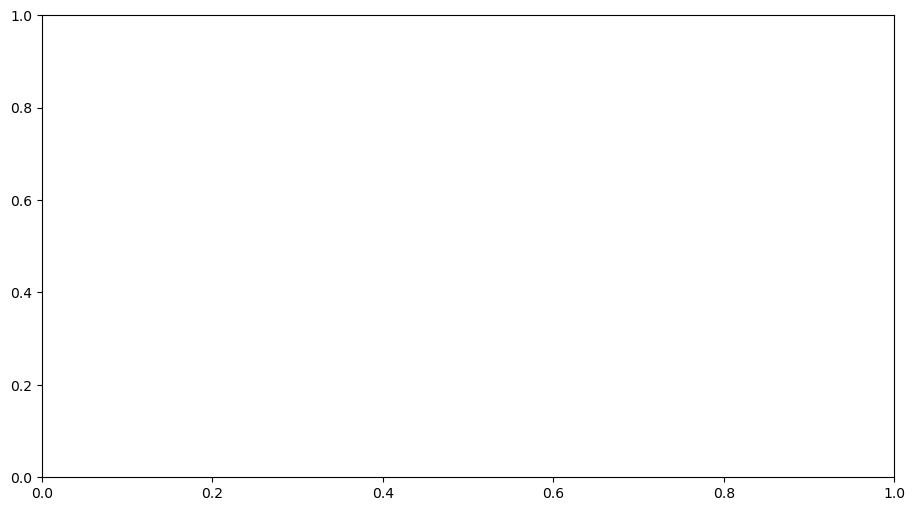

In [5]:
def plot_number_of_holes(ax, df):  # plots number of holes against cutting time

    hole_order = sorted(df["number_of_holes"].unique())  # sorts the hole categories

    df = df.copy()  # creates a copy of the DataFrame

    df["hole_category"] = pd.Categorical(  # converts hole counts into ordered categories
        df["number_of_holes"],
        categories=hole_order,  # sets the category order
        ordered=True
    )

    df["hole_position"] = df["hole_category"].cat.codes  # assigns numbers to categories for regression

    # boxplots
    sns.boxplot(  # shows the cutting time distribution for each category
        data=df,
        x="hole_category",
        y="cutting_time_s",
        order=hole_order,
        color="lightsteelblue",
        showfliers=False,  # hides outliers
        ax=ax
    )

    # regression line + 95% confidence interval
    sns.regplot(  # fits a regression using the individual data points
        data=df,
        x="hole_position",
        y="cutting_time_s",
        scatter=False,  # hides the regression scatter points
        ci=95,  # shows the 95% confidence interval
        n_boot=1000,  # uses 1000 bootstrap samples
        color="red",
        line_kws={"linewidth": 2, "label": "Linear regression"},
        ax=ax
    )

    # individual data points
    sns.stripplot(  # shows the individual observations
        data=df,
        x="hole_category",
        y="cutting_time_s",
        order=hole_order,
        color="darkblue",
        alpha=0.6,
        jitter=0,  # spreads points slightly to avoid overlap
        size=5,
        ax=ax
    )

    ax.set_xticks(range(len(hole_order)))  # sets the x-axis tick positions
    ax.set_xticklabels(hole_order)  # displays the actual hole counts

    ax.set_title("Number of Holes vs. Estimated Cutting Time")  # sets the title
    ax.set_xlabel("Number of Holes")  # labels the x-axis
    ax.set_ylabel("Estimated Cutting Time (seconds)")  # labels the y-axis

    ax.legend()  # shows the regression legend


fig, ax = plt.subplots(figsize=(11, 6))  # creates the figure and axes

plot_number_of_holes(ax, csv_df)  # calls the plotting function

plt.tight_layout()  # adjusts the layout
plt.show()  # displays the plot

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\2333205622.py:49: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


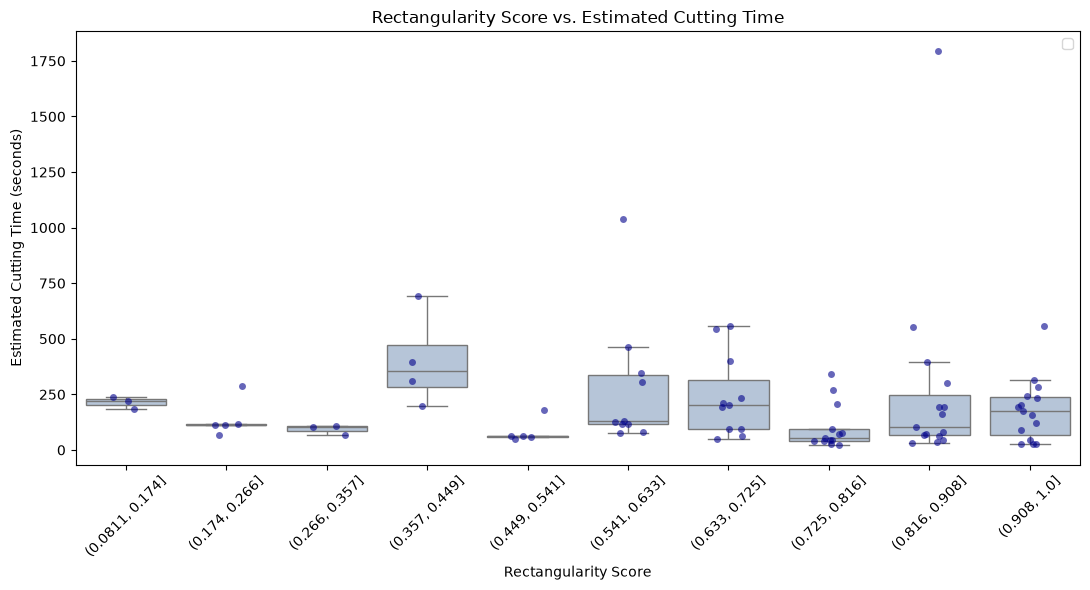

In [ ]:
def plot_rectangularity_score(ax, df):

    df = df.copy()

    # Create bins for rectangularity score
    df["rectangularity_category"] = pd.cut(
        df["rectangularity_score"],
        bins=10
    )

    category_order = sorted(df["rectangularity_category"].dropna().unique())

    df["rectangularity_position"] = pd.Categorical(
        df["rectangularity_category"],
        categories=category_order,
        ordered=True
    ).codes

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="rectangularity_category",
        y="cutting_time_s",
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

   

    # 3. Individual data points
    sns.stripplot(
        data=df,
        x="rectangularity_category",
        y="cutting_time_s",
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Rectangularity Score vs. Estimated Cutting Time")
    ax.set_xlabel("Rectangularity Score")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

    ax.legend()



fig, ax = plt.subplots(figsize=(11, 6))

plot_rectangularity_score(ax, csv_df)

plt.tight_layout()
plt.show()

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\197340510.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


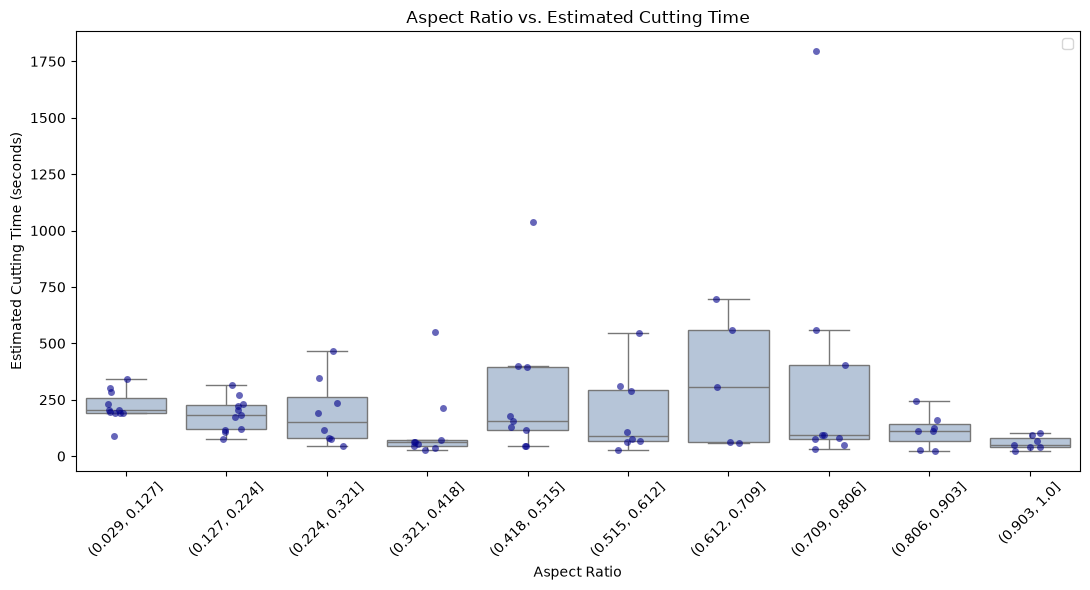

In [ ]:
def plot_aspect_ratio(ax, df):

    df = df.copy()

    # Create bins for aspect ratio
    df["aspect_ratio_category"] = pd.cut(
        df["aspect_ratio"],
        bins=10
    )

    category_order = sorted(df["aspect_ratio_category"].dropna().unique())

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="aspect_ratio_category",
        y="cutting_time_s",
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    

    # 3. Individual data points
    sns.stripplot(
        data=df,
        x="aspect_ratio_category",
        y="cutting_time_s",
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Aspect Ratio vs. Estimated Cutting Time")
    ax.set_xlabel("Aspect Ratio")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

    ax.legend()

fig, ax = plt.subplots(figsize=(11, 6))

plot_aspect_ratio(ax, csv_df)

plt.tight_layout()
plt.show()

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\2189949679.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


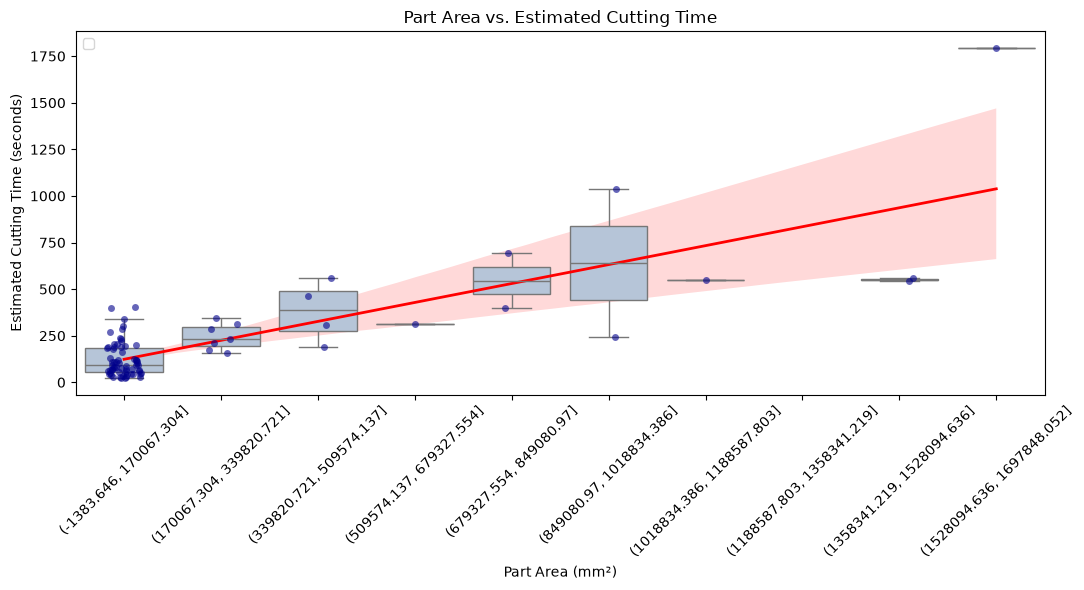

In [ ]:
def plot_part_area(ax, df):

    df = df.copy()

    # Create bins for part area
    df["part_area_category"] = pd.cut(
        df["part_area_mm^2"],
        bins=10
    )

    category_order = sorted(df["part_area_category"].dropna().unique())

    df["part_area_position"] = df["part_area_category"].cat.codes

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="part_area_category",
        y="cutting_time_s",
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    # 2. Regression line + 95% confidence interval
    sns.regplot(
        data=df,
        x="part_area_position",
        y="cutting_time_s",
        scatter=False,
        ci=95,
        n_boot=1000,
        color="red",
        line_kws={"linewidth": 2, "label": "Linear regression"},
        ax=ax
    )

    # 3. Individual data points
    sns.stripplot(
        data=df,
        x="part_area_category",
        y="cutting_time_s",
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Part Area vs. Estimated Cutting Time")
    ax.set_xlabel("Part Area (mm²)")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

    ax.legend()


fig, ax = plt.subplots(figsize=(11, 6))

plot_part_area(ax, csv_df)

plt.tight_layout()
plt.show()

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\85945476.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


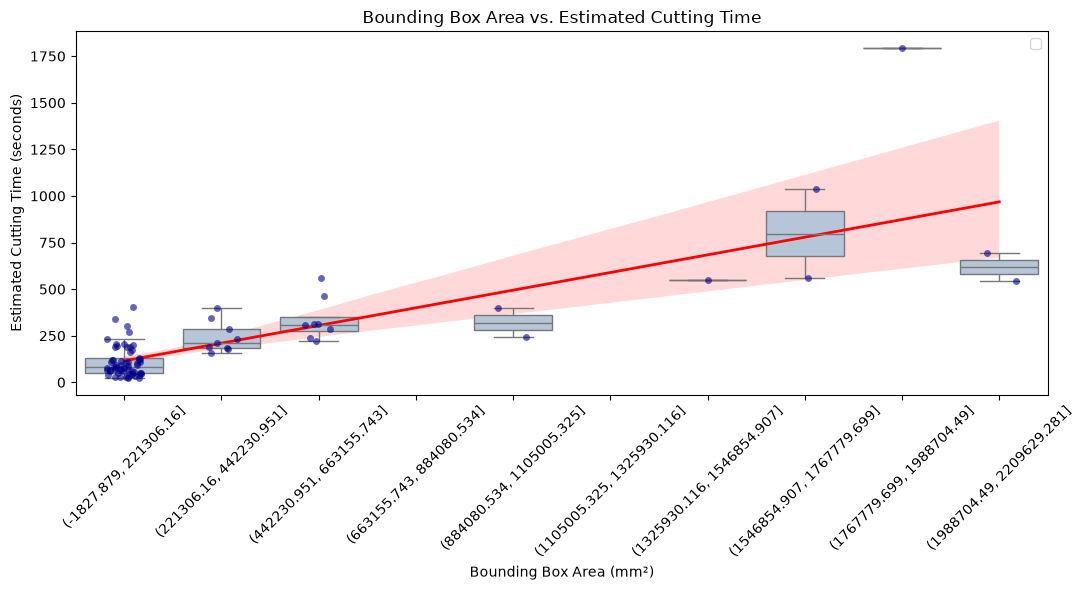

In [ ]:
def plot_bounding_box_area(ax, df):

    df = df.copy()

    # Create bins for bounding box area
    df["bounding_box_area_category"] = pd.cut(
        df["bounding_box_area_mm^2"],
        bins=10
    )

    category_order = sorted(
        df["bounding_box_area_category"].dropna().unique()
    )

    df["bounding_box_position"] = df["bounding_box_area_category"].cat.codes

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="bounding_box_area_category",
        y="cutting_time_s",
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    # 2. Regression line + 95% confidence interval
    sns.regplot(
        data=df,
        x="bounding_box_position",
        y="cutting_time_s",
        scatter=False,
        ci=95,
        n_boot=1000,
        color="red",
        line_kws={"linewidth": 2, "label": "Linear regression"},
        ax=ax
    )

    # 3. Individual data points
    sns.stripplot(
        data=df,
        x="bounding_box_area_category",
        y="cutting_time_s",
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Bounding Box Area vs. Estimated Cutting Time")
    ax.set_xlabel("Bounding Box Area (mm²)")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

    ax.legend()


fig, ax = plt.subplots(figsize=(11, 6))

plot_bounding_box_area(ax, csv_df)

plt.tight_layout()
plt.show()

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\2756623474.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


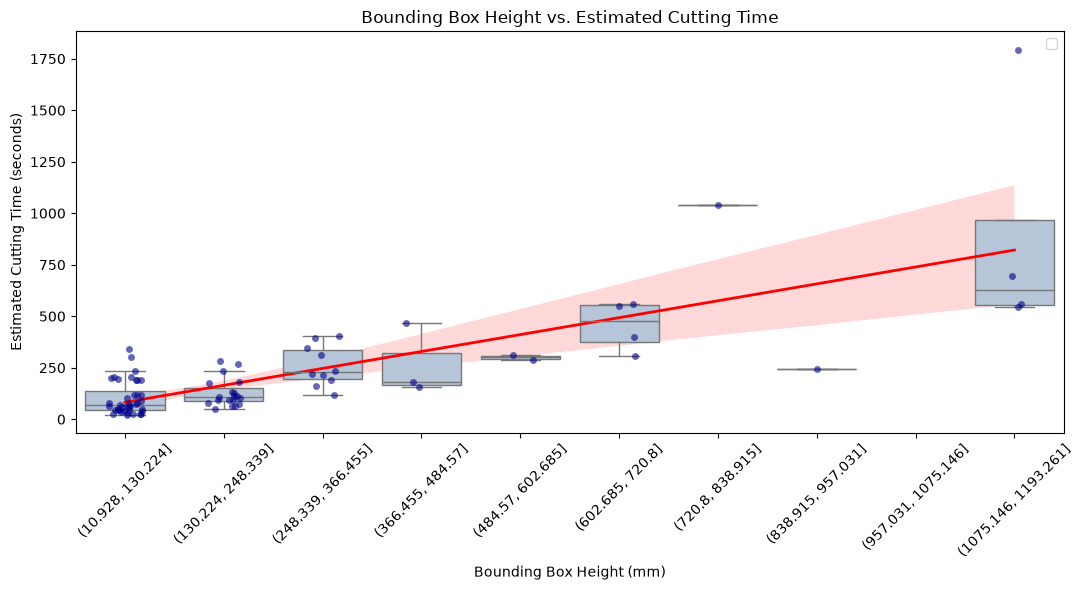

In [ ]:
def plot_bounding_box_height(ax, df):

    df = df.copy()

    # Create bins for bounding box height
    df["bounding_box_height_category"] = pd.cut(
        df["bounding_box_height_mm"],
        bins=10
    )

    category_order = sorted(
        df["bounding_box_height_category"].dropna().unique()
    )

    df["bounding_box_height_position"] = (
        df["bounding_box_height_category"].cat.codes
    )

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="bounding_box_height_category",
        y="cutting_time_s",
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    # 2. Regression line + 95% confidence interval
    sns.regplot(
        data=df,
        x="bounding_box_height_position",
        y="cutting_time_s",
        scatter=False,
        ci=95,
        n_boot=1000,
        color="red",
        line_kws={"linewidth": 2, "label": "Linear regression"},
        ax=ax
    )

    # 3. Individual data points
    sns.stripplot(
        data=df,
        x="bounding_box_height_category",
        y="cutting_time_s",
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Bounding Box Height vs. Estimated Cutting Time")
    ax.set_xlabel("Bounding Box Height (mm)")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

    ax.legend()

fig, ax = plt.subplots(figsize=(11, 6))

plot_bounding_box_height(ax, csv_df)

plt.tight_layout()
plt.show()

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\3370453465.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


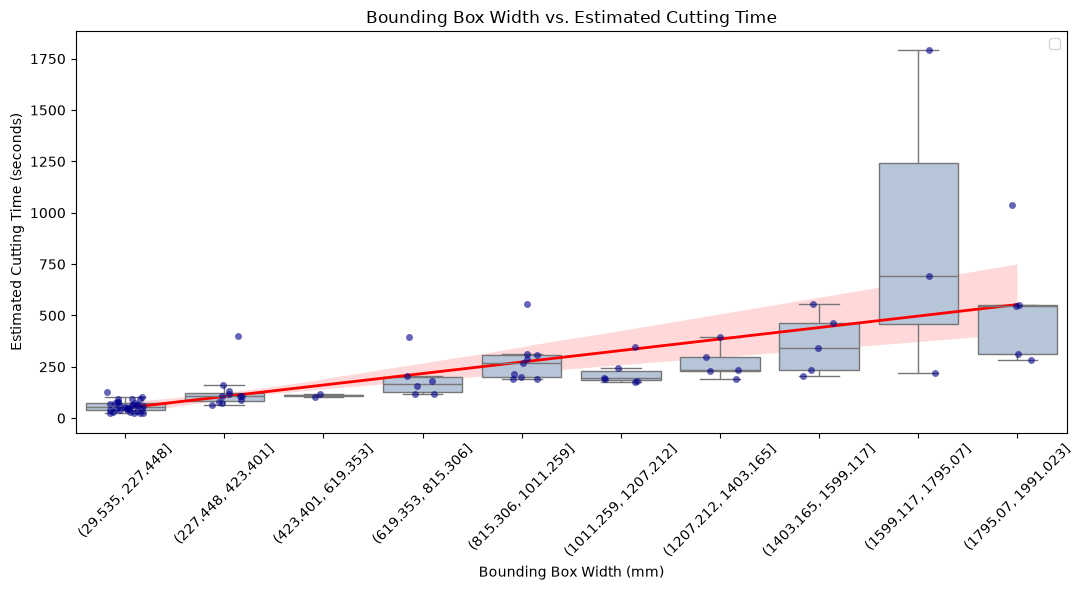

In [ ]:
def plot_bounding_box_width(ax, df):

    df = df.copy()

    # Create bins for bounding box width
    df["bounding_box_width_category"] = pd.cut(
        df["bounding_box_width_mm"],
        bins=10
    )

    category_order = sorted(
        df["bounding_box_width_category"].dropna().unique()
    )

    df["bounding_box_width_position"] = (
        df["bounding_box_width_category"].cat.codes
    )

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="bounding_box_width_category",
        y="cutting_time_s",
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    # 2. Regression line + 95% confidence interval
    sns.regplot(
        data=df,
        x="bounding_box_width_position",
        y="cutting_time_s",
        scatter=False,
        ci=95,
        n_boot=1000,
        color="red",
        line_kws={"linewidth": 2, "label": "Linear regression"},
        ax=ax
    )

    # 3. Individual data points
    sns.stripplot(
        data=df,
        x="bounding_box_width_category",
        y="cutting_time_s",
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Bounding Box Width vs. Estimated Cutting Time")
    ax.set_xlabel("Bounding Box Width (mm)")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

    ax.legend()

fig, ax = plt.subplots(figsize=(11, 6))

plot_bounding_box_width(ax, csv_df)

plt.tight_layout()
plt.show()

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\4113968351.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


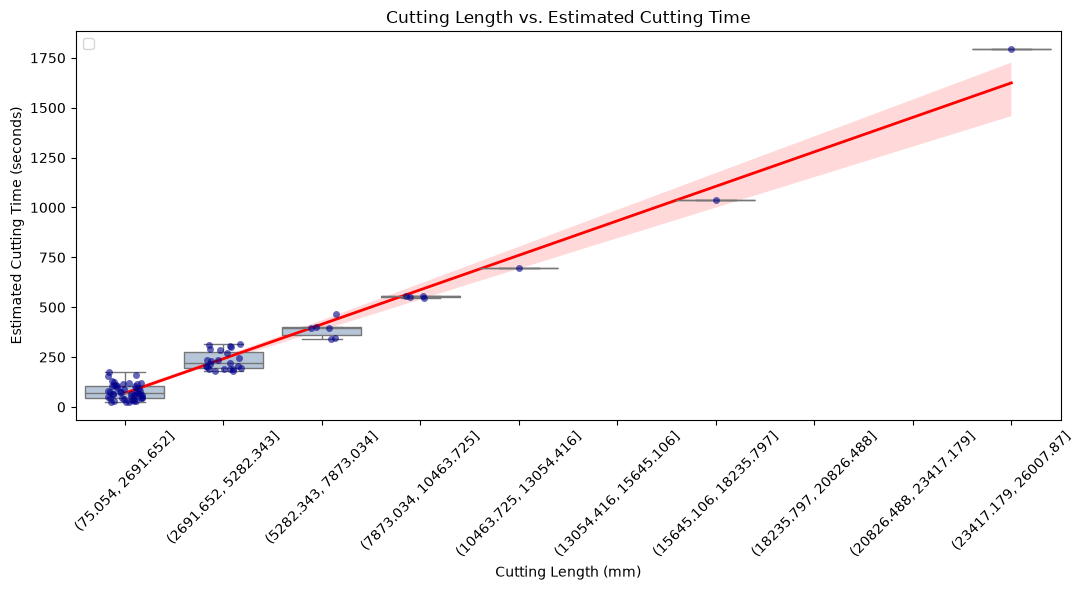

In [ ]:
def plot_cutting_length(ax, df):

    df = df.copy()

    # Create bins for cutting length
    df["cutting_length_category"] = pd.cut(
        df["cutting_length_mm"],
        bins=10
    )

    category_order = sorted(
        df["cutting_length_category"].dropna().unique()
    )

    df["cutting_length_position"] = (
        df["cutting_length_category"].cat.codes
    )

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="cutting_length_category",
        y="cutting_time_s",
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    # 2. Regression line + 95% confidence interval
    sns.regplot(
        data=df,
        x="cutting_length_position",
        y="cutting_time_s",
        scatter=False,
        ci=95,
        n_boot=1000,
        color="red",
        line_kws={"linewidth": 2, "label": "Linear regression"},
        ax=ax
    )

    # 3. Individual data points
    sns.stripplot(
        data=df,
        x="cutting_length_category",
        y="cutting_time_s",
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Cutting Length vs. Estimated Cutting Time")
    ax.set_xlabel("Cutting Length (mm)")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

    ax.legend()

fig, ax = plt.subplots(figsize=(11, 6))

plot_cutting_length(ax, csv_df)

plt.tight_layout()
plt.show()

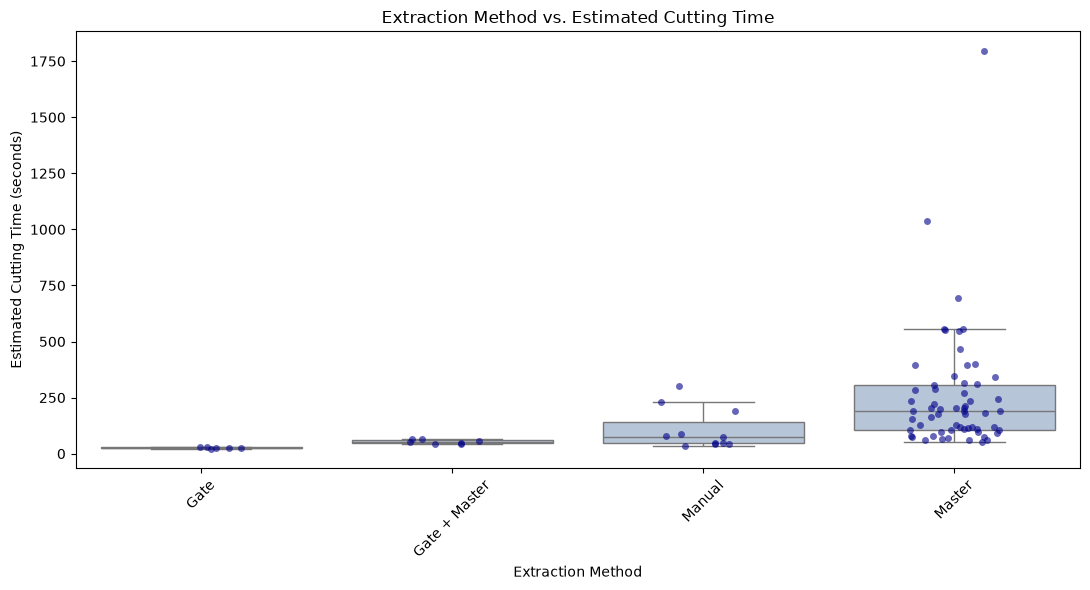

In [ ]:
def plot_extraction_method(ax, df):

    df = df.copy()

    # Define category order
    method_order = sorted(df["extraction_method"].unique())

    # 1. Boxplots
    sns.boxplot(
        data=df,
        x="extraction_method",
        y="cutting_time_s",
        order=method_order,
        color="lightsteelblue",
        showfliers=False,
        ax=ax
    )

    # 2. Individual data points
    sns.stripplot(
        data=df,
        x="extraction_method",
        y="cutting_time_s",
        order=method_order,
        color="darkblue",
        alpha=0.6,
        jitter=0.18,
        size=5,
        ax=ax
    )

    ax.set_title("Extraction Method vs. Estimated Cutting Time")
    ax.set_xlabel("Extraction Method")
    ax.set_ylabel("Estimated Cutting Time (seconds)")

    ax.tick_params(axis="x", rotation=45)

fig, ax = plt.subplots(figsize=(11, 6))

plot_extraction_method(ax, csv_df)

plt.tight_layout()
plt.show()

In [ ]:
plot_df = csv_df.copy()

C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\2333205622.py:49: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\197340510.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\2074057522.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\cozmi\AppData\Local\Temp\ipykernel_14992\2189949679.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.le

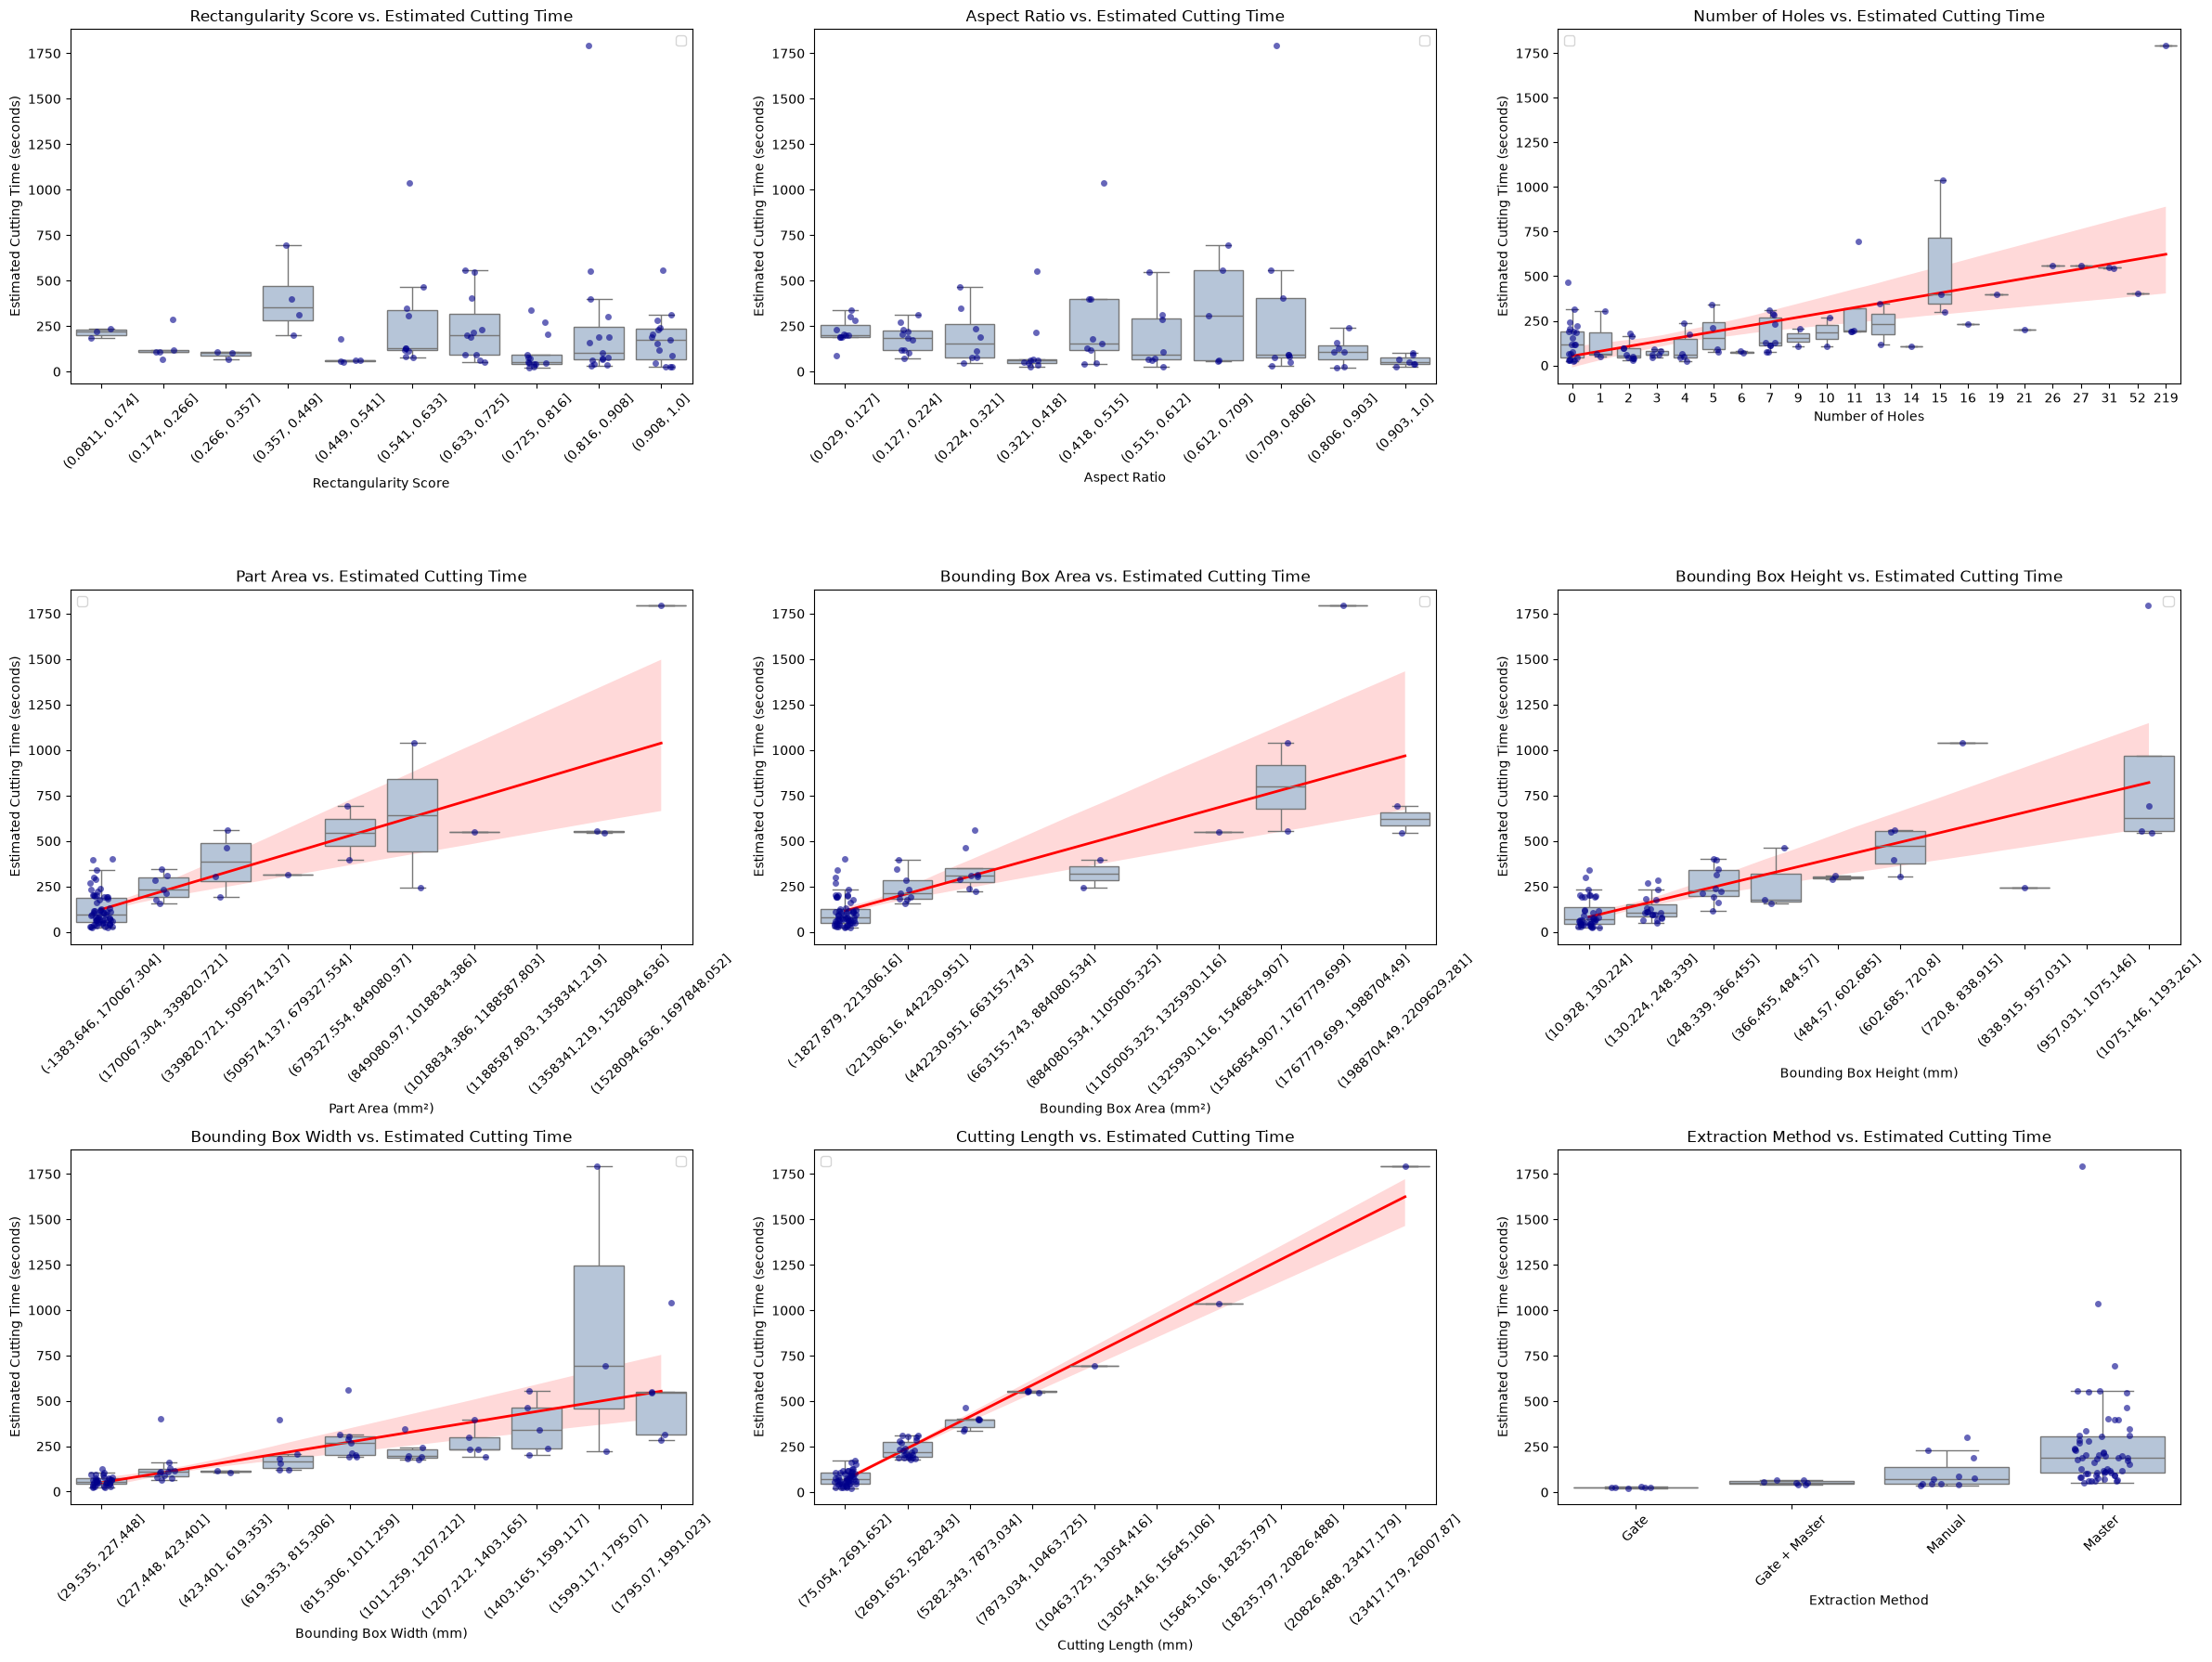

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(24, 18))

# Flatten axes for easier access
axes = axes.flatten()

# Plot all features
plot_rectangularity_score(axes[0], plot_df)
plot_aspect_ratio(axes[1], plot_df)
plot_number_of_holes(axes[2], plot_df)

plot_part_area(axes[3], plot_df)
plot_bounding_box_area(axes[4], plot_df)
plot_bounding_box_height(axes[5], plot_df)

plot_bounding_box_width(axes[6], plot_df)
plot_cutting_length(axes[7], plot_df)
plot_extraction_method(axes[8], plot_df)

plt.tight_layout()
plt.show()